In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import AgglomerativeClustering, KMeans
import seaborn as sns
import os
os.chdir("E:/Vishal_Adesh/CDAC/Machine Learning/Datasets")
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

In [2]:
df = pd.read_csv("nutrient.csv",index_col=0)
df.head()

,energy,protein,fat,calcium,iron
Food_Item,,,,,
BEEF BRAISED,340,20,28,9,2.6
HAMBURGER,245,21,17,9,2.7
BEEF ROAST,420,15,39,7,2.0
BEEF STEAK,375,19,32,9,2.6
BEEF CANNED,180,22,10,17,3.7


In [3]:
scaler = StandardScaler().set_output(transform='pandas')
scl_df = scaler.fit_transform(df)

In [4]:
km = KMeans(n_clusters=5, random_state=26)
km.fit(scl_df)
km.labels_

array([0, 2, 0, 0, 2, 2, 2, 4, 0, 0, 0, 0, 0, 2, 2, 2, 3, 3, 2, 2, 2, 1,
       2, 1, 1, 2, 2], dtype=int32)

In [5]:
km.inertia_

32.7495278605748

In [6]:
ks = np.arange(1,21)
wss = []
for k in ks:
    km = KMeans(n_clusters=k,random_state=26)
    km.fit(scl_df)
    wss.append([k,km.inertia_])
df_wss = pd.DataFrame(wss,columns=["K","Score"])
df_wss.sort_values("Score",ascending=True)

,K,Score
19,20,0.839840
18,19,1.122538
17,18,1.443949
16,17,1.748907
15,16,2.068435
14,15,2.652684
13,14,3.103618
12,13,3.630331
11,12,5.484802
10,11,6.777566


## Elbow Method [Scree Plot]

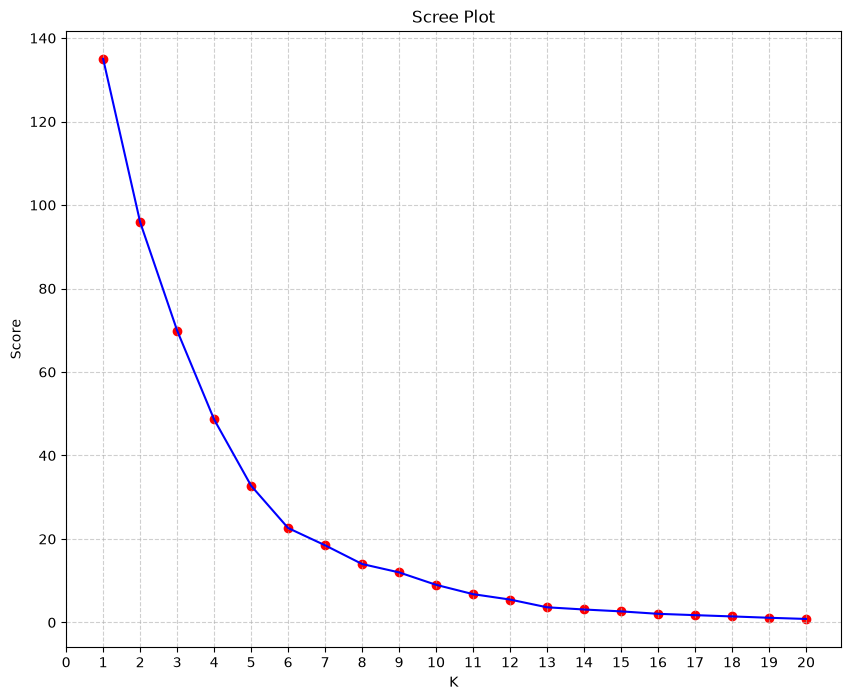

In [21]:
plt.figure(figsize=(10,8))
plt.scatter(df_wss["K"],df_wss["Score"],c='red')
plt.plot(df_wss["K"],df_wss["Score"],c='blue')
plt.title("Scree Plot")
plt.xticks(range(0, 21))
plt.xlabel("K")
plt.ylabel("Score")
plt.grid(True,linestyle='--',alpha=0.6)
plt.show()

Recommended optimal K: 6


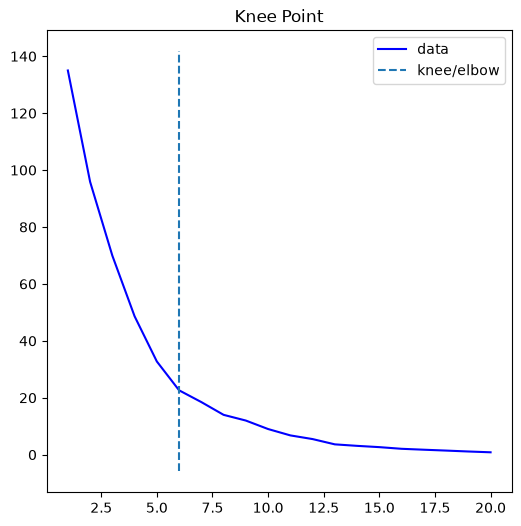

In [23]:
from kneed import KneeLocator
# Automatically find and print the optimal elbow point
kl = KneeLocator(
    df_wss["K"], 
    df_wss["Score"], 
    curve="convex", 
    direction="decreasing"
)

print(f"Recommended optimal K: {kl.elbow}")

# Optional: Plot the knee detection curve
kl.plot_knee()
plt.show()

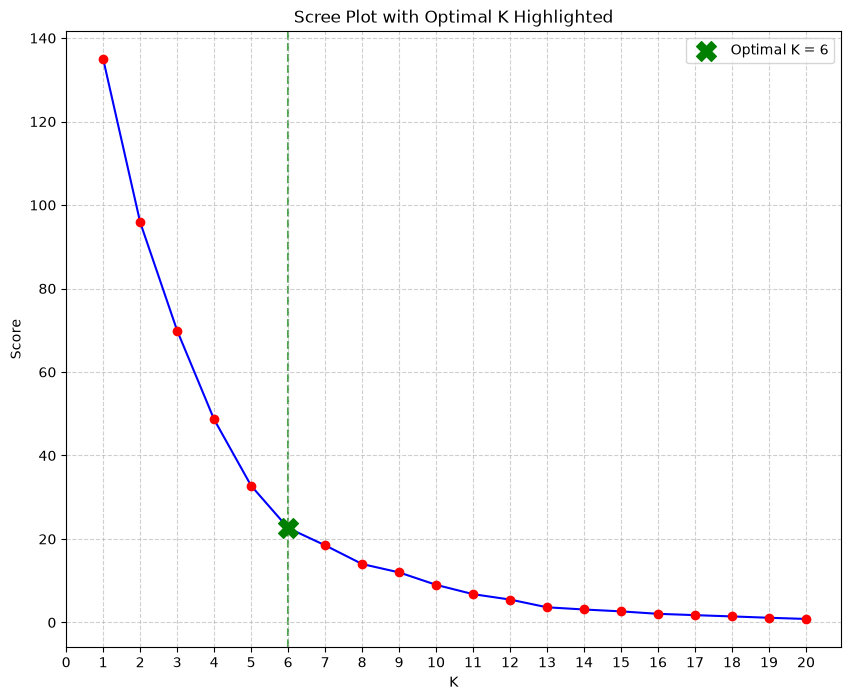

Recommended optimal K: 6


In [22]:
from kneed import KneeLocator

# 1. Compute the knee point
kl = KneeLocator(
    df_wss["K"], 
    df_wss["Score"], 
    curve="convex", 
    direction="decreasing"
)
optimal_k = kl.elbow
optimal_score = df_wss.loc[df_wss["K"] == optimal_k, "Score"].values[0]

# 2. Plot the Scree Plot
plt.figure(figsize=(10, 8))
plt.scatter(df_wss["K"], df_wss["Score"], c='red', zorder=3)
plt.plot(df_wss["K"], df_wss["Score"], c='blue', zorder=2)

# 3. Highlight the optimal K point on the same plot
plt.scatter(optimal_k, optimal_score, color='green', s=200, marker='X', zorder=4, label=f'Optimal K = {optimal_k}')
plt.axvline(x=optimal_k, color='green', linestyle='--', alpha=0.7, zorder=1)

plt.title("Scree Plot with Optimal K Highlighted")
plt.xticks(range(0, 21))
plt.xlabel("K")
plt.ylabel("Score")
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

print(f"Recommended optimal K: {optimal_k}")